# Beyond Static Models: Evaluating Drift-Aware Retraining for Time-Series Anomaly Detection
# Starling 🌟
***Starling is a time-series anomaly detection research project. Its goal is to investigate how different retraining strategies affect anomaly detection when time-series data changes over time.We use NASA SMAP/MSL telemetry data from [Telemanom](https://github.com/khundman/telemanom).***

## Description
This file has been made to do some researches on data and also get some valuable informations from it. <br>
The Repo explores NASA-SMAP/MSL data for Anomaly Detection.

### Dependencies

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import numpy as np
from dotenv import load_dotenv
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
load_dotenv()

True

### Data Exploration -> Load

In [4]:
train_data_dir = os.getenv("train_data_dir")
test_data_dir = os.getenv('test_data_dir')
for file_path in Path(train_data_dir).rglob("*.npy"):
    data = np.load(file_path,mmap_mode="r")
    # print(f"\nFile name: {file_path.name}")
    # print(f'data shape: {data.shape}')
    # print('==============================')
    # print(f'data type: {data.dtype}')
    # print('==============================')
    # print(f'First values: ')
    # print(data[:5])



In [5]:
meta_data = pd.read_csv(os.getenv('meta_data'))
print("Spacecraft counts:")
print(meta_data["spacecraft"].value_counts())

print("\nChannels per spacecraft:")
print(
    meta_data.groupby("spacecraft")["chan_id"]
    .agg(["count", "nunique"])
)

print("\nExample channels:")
display(
    meta_data[["chan_id", "spacecraft", "class", "num_values"]]
    
)



duplicates = meta_data[
    meta_data["chan_id"].duplicated(keep=False)
].sort_values("chan_id")

display(duplicates)

Spacecraft counts:
spacecraft
SMAP    55
MSL     27
Name: count, dtype: int64

Channels per spacecraft:
            count  nunique
spacecraft                
MSL            27       27
SMAP           55       54

Example channels:


,chan_id,spacecraft,class,num_values
0,P-1,SMAP,"[contextual, contextual, contextual]",8505
1,S-1,SMAP,[point],7331
2,E-1,SMAP,"[contextual, contextual]",8516
3,E-2,SMAP,[point],8532
4,E-3,SMAP,[point],8307
...,...,...,...,...
77,P-11,MSL,"[point, point]",3535
78,D-15,MSL,[point],2158
79,D-16,MSL,[contextual],2191
80,M-7,MSL,[point],2156


,chan_id,spacecraft,anomaly_sequences,class,num_values
17,P-2,SMAP,"[[5350, 6575]]",[point],8209
51,P-2,SMAP,"[[5300, 6420]]",[point],8209


## 1. Overview
| Item | Result |
|---|---|
| Training channels | 82 |
| Test channels | 82 |
| Data format | NumPy (`.npy`) |
| Target signal | First feature: `data[:, 0]` |
| Anomaly labels | `labeled_anomalies.csv` |

## 2. Validation Results

- All 82 training channels have corresponding test files.
- Arrays contain finite values and matching train/test feature dimensions.
- Anomaly intervals fit within their corresponding test sequences.
- `P-2` has two annotation rows; both are preserved.
- `T-10` has no labels and is excluded from labeled evaluation.

## 3. Important Findings

| Finding | Result |
|---|---|
| Constant training signals | 16 channels |
| Target values outside `[-1, 1]` | 18 train, 21 test channels |
| Severe train/test mismatch | `M-6`: constant training signal, test maximum ≈ 258.11 |

These findings require investigation. **No data has been modified, and no model has been trained yet.**

## 4. Next Steps

1. Visualize `P-2` and its labeled anomaly intervals.
2. Investigate the `M-6` mismatch.
3. Train a baseline anomaly detector.
4. Compare retraining strategies.
5. Introduce MLflow, Airflow, and Docker.

## Visualization

Signal length: 8209
Anomaly intervals:
[[5350, 6575]]
[[5300, 6420]]


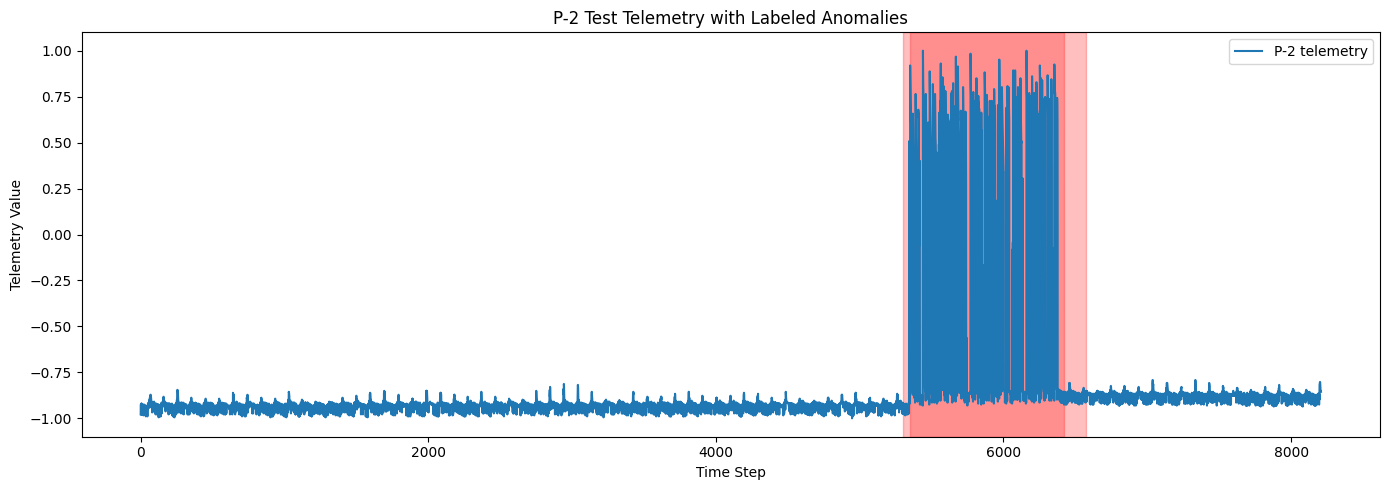

'\nthis plot confirms that the P-2 signal has anomalous signals \n'

In [6]:
# Load P-2 test data
data = np.load(f'{test_data_dir}/P-2.npy')
signal = data[:, 0]

labels = pd.read_csv(os.getenv('meta_data'))
p2_labels = labels[labels["chan_id"] == "P-2"]

print("Signal length:", len(signal))
print("Anomaly intervals:")
print(p2_labels["anomaly_sequences"].to_string(index=False))
plt.figure(figsize=(14, 5))

plt.plot(signal, label="P-2 telemetry")

# Highlight labeled anomaly intervals
for _, row in p2_labels.iterrows():
    intervals = row["anomaly_sequences"]

    # Convert the annotation string into Python lists
    if isinstance(intervals, str):
        intervals = eval(intervals)

    for start, end in intervals:
        plt.axvspan(start, end, alpha=0.25, color="red")

plt.title("P-2 Test Telemetry with Labeled Anomalies")
plt.xlabel("Time Step")
plt.ylabel("Telemetry Value")
plt.legend()
plt.tight_layout()
plt.show()
"""
this plot confirms that the P-2 signal has anomalous signals 
"""

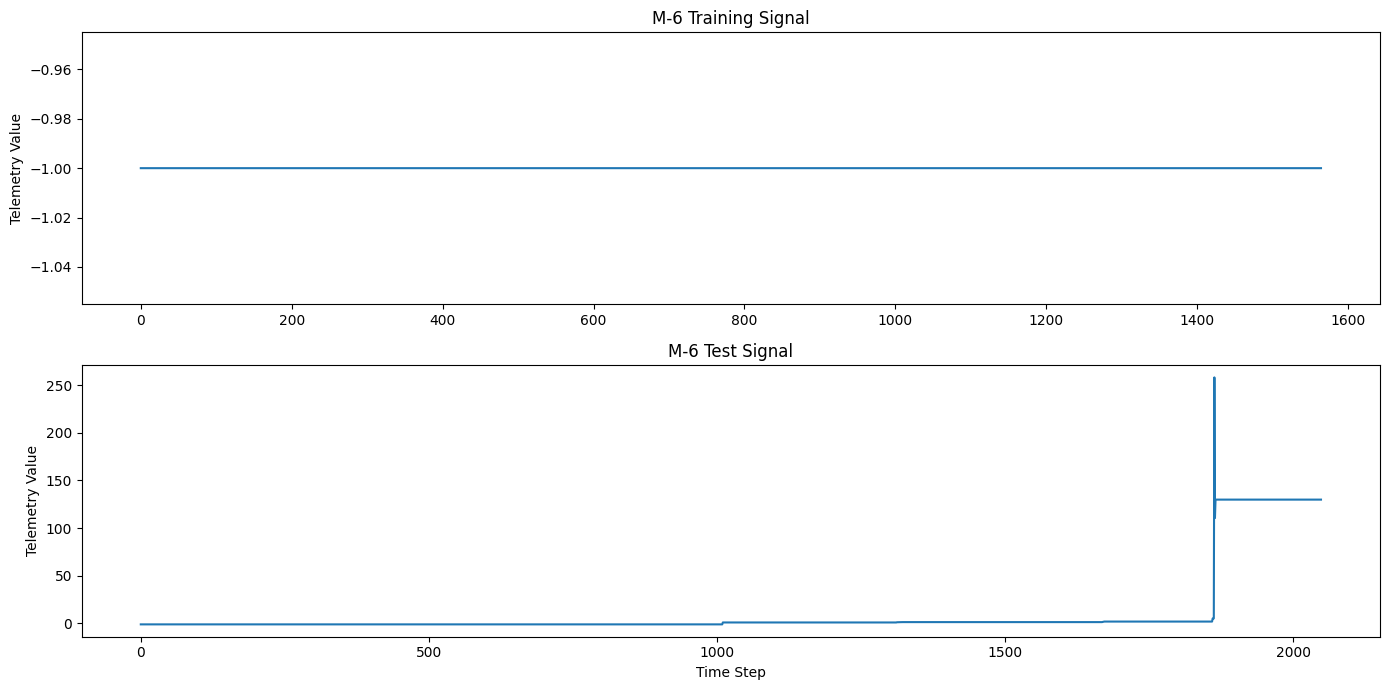

'\nM-6 plot shows that there are differences between train and test signals which is related to data issue or preprocessing\n'

In [7]:
train = np.load("data/train/M-6.npy")[:, 0]
test = np.load("data/test/M-6.npy")[:, 0]

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

axes[0].plot(train)
axes[0].set_title("M-6 Training Signal")
axes[0].set_ylabel("Telemetry Value")

axes[1].plot(test)
axes[1].set_title("M-6 Test Signal")
axes[1].set_xlabel("Time Step")
axes[1].set_ylabel("Telemetry Value")

plt.tight_layout()
plt.show()

"""
M-6 plot shows that there are differences between train and test signals which is related to data issue or preprocessing
"""

### P-2 Baseline
1. Calculate the rolling median.
2. Measure how far each observation deviates from that median.
3. Flag unusually large deviations.
4. Compare the predictions with the labeled anomalies.

number of observations:  8209


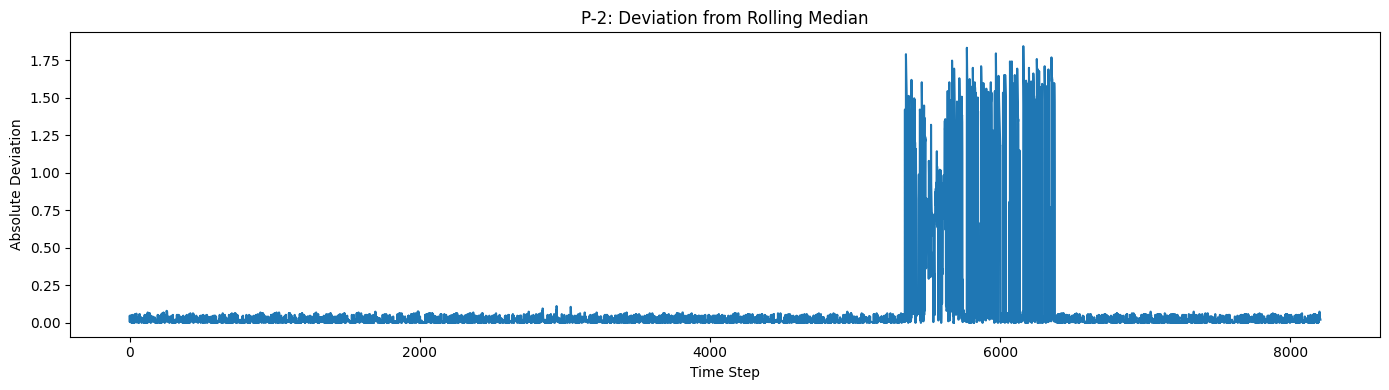

In [8]:
P_2_signal = np.load(f'{test_data_dir}/P-2.npy')[:,0]
print('number of observations: ', len(P_2_signal))

window_size = 101

series = pd.Series(signal)

rolling_median = series.rolling(
    window=window_size,
    center=True,
    min_periods=1
).median()


deviation = np.abs(signal - rolling_median)

plt.figure(figsize=(14, 4))
plt.plot(deviation)
plt.title("P-2: Deviation from Rolling Median")
plt.xlabel("Time Step")
plt.ylabel("Absolute Deviation")
plt.tight_layout()
plt.show()

Threshold: 0.05827170032374953
Potential anomalies: 988


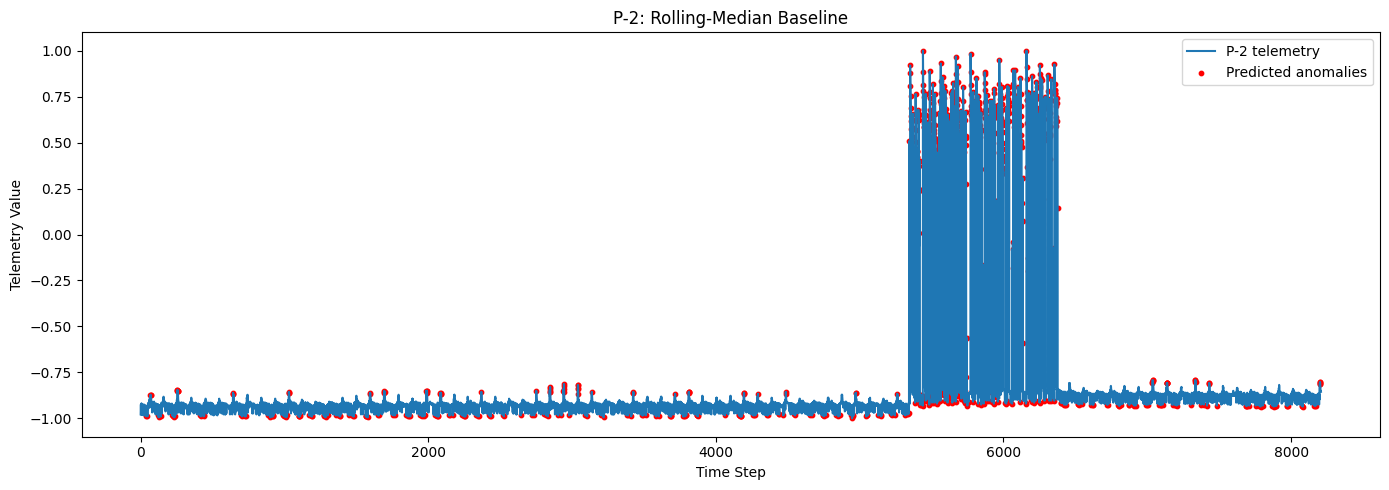

In [9]:
deviation_median = np.median(deviation)
mad = np.median(np.abs(deviation - deviation_median))

threshold = deviation_median + 6 * 1.4826 * mad

predictions = deviation > threshold

print("Threshold:", threshold)
print("Potential anomalies:", predictions.sum())


plt.figure(figsize=(14, 5))

plt.plot(signal, label="P-2 telemetry")

plt.scatter(
    np.where(predictions)[0],
    signal[predictions],
    color="red",
    s=10,
    label="Predicted anomalies"
)

plt.title("P-2: Rolling-Median Baseline")
plt.xlabel("Time Step")
plt.ylabel("Telemetry Value")
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
import numpy as np
import pandas as pd

# Reuse `signal` and `predictions` from your earlier cells
labels = pd.read_csv("data/labeled_anomalies.csv")
print(labels[labels["chan_id"] == "P-2"][["chan_id", "anomaly_sequences"]])

# Build a point-level ground-truth mask (union of both P-2 intervals)
truth = np.zeros(len(signal), dtype=bool)
for start, end in [(5350, 6575), (5300, 6420)]:
    truth[start:end + 1] = True

print("Signal length:        ", len(signal))
print("Labeled anomaly points:", truth.sum())
print("Predicted anomalies:   ", predictions.sum())
print("Predicted inside label:", (predictions & truth).sum())
print("Predicted outside label:", (predictions & ~truth).sum())

   chan_id anomaly_sequences
17     P-2    [[5350, 6575]]
51     P-2    [[5300, 6420]]
Signal length:         8209
Labeled anomaly points: 1276
Predicted anomalies:    988
Predicted inside label: 669
Predicted outside label: 319


In [11]:
# Reuse `signal`, `predictions`, `truth`, `deviation`, `threshold`
print("Threshold:", threshold)
print("Deviation quantiles (50/90/99/99.9%):",
      np.quantile(deviation, [0.5, 0.9, 0.99, 0.999]).round(4))

regions = {
    "before 5300":  (0, 5299),
    "5300-5349":    (5300, 5349),
    "5350-6419":    (5350, 6419),
    "6420-6575":    (6420, 6575),
    "after 6575":   (6576, len(signal) - 1),
}

for name, (a, b) in regions.items():
    n = b - a + 1
    flagged = predictions[a:b + 1].sum()
    print(f"{name:12s}  length={n:5d}  flagged={flagged:4d}  ({flagged / n:.1%})")

Threshold: 0.05827170032374953
Deviation quantiles (50/90/99/99.9%): [0.0107 0.0588 1.5775 1.7476]
before 5300   length= 5300  flagged= 242  (4.6%)
5300-5349     length=   50  flagged=   5  (10.0%)
5350-6419     length= 1070  flagged= 656  (61.3%)
6420-6575     length=  156  flagged=   8  (5.1%)
after 6575    length= 1633  flagged=  77  (4.7%)


In [12]:
train = np.load("data/train/P-2.npy")[:, 0]
quiet = signal[:5300]          # test signal before any label starts

def summary(name, x):
    print(f"{name:14s} n={len(x):5d}  min={x.min():.4f}  max={x.max():.4f}  "
          f"mean={x.mean():.4f}  std={x.std():.4f}  unique={len(np.unique(x))}")

summary("train", train)
summary("test 0-5299", quiet)
summary("test all", signal)

# Quantization check: deviations just above the threshold
band = (deviation > threshold) & (deviation <= 0.0588)
print("Deviations in (threshold, 0.0588]:", band.sum())

train          n= 2821  min=-1.0000  max=-0.8400  mean=-0.9433  std=0.0284  unique=33
test 0-5299    n= 5300  min=-1.0000  max=-0.8128  mean=-0.9292  std=0.0226  unique=36
test all       n= 8209  min=-1.0000  max=1.0000  mean=-0.8273  std=0.3488  unique=202
Deviations in (threshold, 0.0588]: 0


In [13]:
from starling.data_load import load_channel

for chan in ["P-2", "T-10", "M-6"]:
    train, test, intervals = load_channel(chan, data_dir="data")
    print(f"{chan:5s} train={len(train):5d}  test={len(test):5d}  intervals={intervals}")

P-2   train= 2821  test= 8209  intervals=[[5350, 6575], [5300, 6420]]
T-10  train=  425  test=  670  intervals=[]
M-6   train= 1565  test= 2049  intervals=[[1850, 2030]]
